# 개발환경 실습: 새 연습 폴더 점검하기

**이 노트북에서 할 일**

1. 임시 폴더에 새 연습 폴더 `practice`를 만들고, 파일 두 개를 넣어 Git으로 기록합니다.
2. 1~5절에서 배운 확인 여섯 가지로 점검표를 만들고, 작업 폴더를 practice로 두고 점검합니다(실행 1).
3. 작업 폴더만 한 칸 위로 바꿔 같은 점검을 하고, 달라진 칸을 비교합니다(실행 2).

**준비물** — API 키 불필요. 데이터 파일도 없습니다. 노트북이 임시 폴더에 연습 폴더를 직접 만듭니다.
모델 호출은 0번이고 비용은 들지 않습니다. 실행 시간은 1분 이내입니다.

2절에서 설치한 Git이 필요합니다. 노트북은 Docker가 없어도 끝까지 실행됩니다.
커널은 3절에서 준비한 실습 폴더의 `.venv`를 고릅니다.

## 오늘 볼 그림

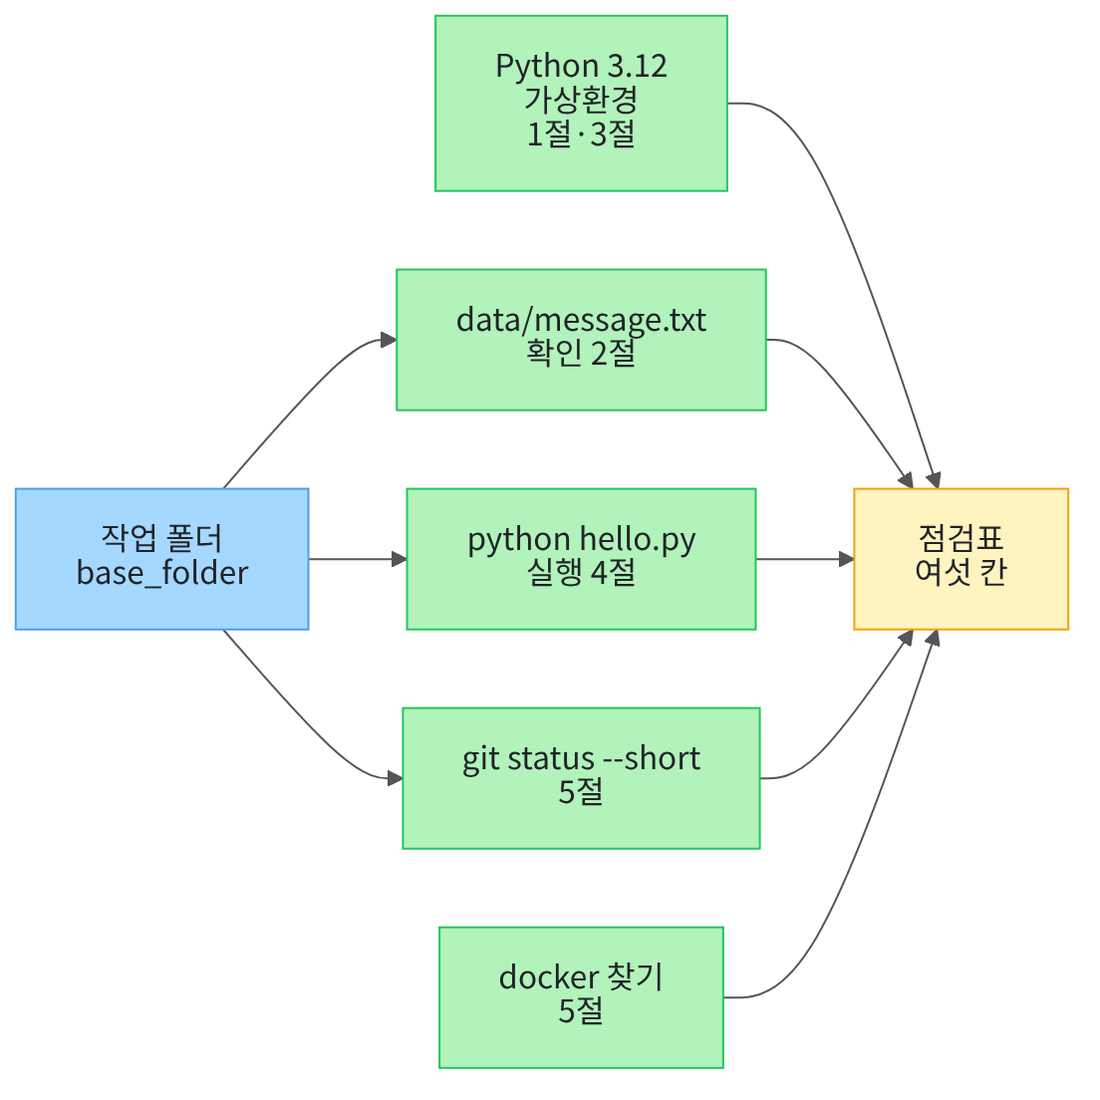

왼쪽에서 오른쪽으로 읽습니다. 파란 상자는 우리가 고르는 작업 폴더이고, 초록 상자는 1~5절에서 배운 확인입니다.
작업 폴더에서 화살표를 받는 확인은 가운데 세 개입니다.
초록 상자는 다섯 개이고, 맨 위 상자에 Python 3.12와 가상환경 두 확인이 함께 들어 있습니다. 여섯 확인의 결과는 모두 오른쪽 노란 점검표로 모입니다.

## 1. 준비

이 절도 설치할 패키지가 없습니다. 5절에서 쓴 기본 기능 여섯 가지를 그대로 불러옵니다.
새로 배우는 문법이나 기능은 없습니다. 모두 1~5절에서 한 번씩 써 본 이름입니다.

In [1]:
# 이 절에서 쓰는 Python 기본 기능을 불러옵니다
import platform
import shutil
import subprocess
import sys
import tempfile
from pathlib import Path

print("불러오기 완료")

불러오기 완료


**결과 읽기** — `불러오기 완료`가 보이면 다음 셀로 넘어갑니다.

## 2. 실습 주제 — 새 연습 폴더 점검하기

다음 장부터는 새 실습 폴더를 열고 노트북을 실행합니다. 실행하기 전에 폴더와 도구가 준비됐는지 이 점검표 순서로 먼저 확인해 볼 수 있습니다.
이번 실습은 1~5절에서 따로 배운 확인 여섯 가지를 한 점검표로 모읍니다.

점검할 연습 폴더는 노트북이 직접 만듭니다. 2절처럼 임시 폴더 `workspace` 안에 `practice` 폴더를 만듭니다.
그 안에 `data` 폴더와 `message.txt` 파일도 2절과 같은 글로 넣습니다.

In [2]:
# 2절처럼 임시 폴더 안에 practice 폴더와 data/message.txt 파일을 만듭니다
temporary_folder = tempfile.TemporaryDirectory()
workspace = Path(temporary_folder.name)
project = workspace / "practice"
project.mkdir()
data_folder = project / "data"
data_folder.mkdir()
message_file = data_folder / "message.txt"
message_file.write_text("안녕, 터미널!", encoding="utf-8")
print("practice 폴더가 있는가:", project.is_dir())
print("message.txt 파일이 있는가:", message_file.is_file())

practice 폴더가 있는가: True
message.txt 파일이 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다. 임시 폴더 안에 practice, data, message.txt가 차례로 들어 있습니다.

다음은 4절의 `hello.py`와 같은 네 줄을 practice 폴더에 저장합니다.

In [3]:
# 4절의 hello.py와 같은 네 줄을 practice 폴더에 저장합니다
hello_source = """price = 3000
count = 2
total = price * count
print(f"총액: {total}원")
"""
hello_file = project / "hello.py"
hello_file.write_text(hello_source, encoding="utf-8")
print("hello.py가 있는가:", hello_file.is_file())

hello.py가 있는가: True


**결과 읽기** — `True`입니다. 연습 폴더에 파일 두 개가 준비됐습니다.

이제 5절의 순서대로 practice 폴더를 Git 저장소로 만듭니다. 명령 git을 찾지 못하면 검사 줄 `assert`에서 멈춥니다.
인자 `cwd=project`는 git을 practice 폴더에서 실행하게 합니다.

In [4]:
# 5절처럼 git을 찾고, practice 폴더에서 git init을 실행합니다
git_path = shutil.which("git")
assert git_path is not None
init_command = [git_path, "init"]
init_run = subprocess.run(init_command, cwd=project, capture_output=True, text=True)
git_folder = project / ".git"
print("git init 종료 코드:", init_run.returncode)
print(".git 폴더가 있는가:", git_folder.is_dir())

git init 종료 코드: 0
.git 폴더가 있는가: True


**결과 읽기** — git init 종료 코드는 `0`이고, `.git` 폴더가 있는지는 `True`입니다.

두 파일을 기록할 목록에 올리고 커밋합니다. 5절처럼 옵션 `-c`로 이번 명령에만 쓸 이름과 전자우편을 넣습니다.
명령 `git add` 뒤에는 파일 이름을 여러 개 이어 적을 수 있습니다.

In [5]:
# 두 파일을 기록할 목록에 올리고, 이번 명령에만 쓸 이름으로 커밋합니다
add_command = [git_path, "add", "hello.py", "data/message.txt"]
subprocess.run(add_command, cwd=project, check=True)
name_setting = "user.name=Ch1 Student"
email_setting = "user.email=student@example.com"
commit_command = [
    git_path, "-c", name_setting, "-c", email_setting,
    "commit", "--quiet", "-m", "연습 폴더 첫 기록",
]
commit_run = subprocess.run(commit_command, cwd=project, capture_output=True, text=True)
print("커밋 종료 코드:", commit_run.returncode)

커밋 종료 코드: 0


**결과 읽기** — 커밋 종료 코드는 `0`입니다. 새 연습 폴더가 파일 두 개와 첫 기록을 갖췄습니다.

## 3. 점검표 칸 정하기

점검 결과를 한눈에 보려면 결과를 적을 자리가 필요합니다. 1절의 과정 지도처럼 칸 이름 여섯 개를 목록에 순서대로 담습니다.
칸마다 어느 절에서 배운 확인인지 주석으로 적었습니다. 실행 1과 실행 2는 이 순서대로 결과를 적습니다.

In [6]:
# 점검표의 여섯 칸 이름을 순서대로 목록에 담습니다
check_names = [
    "Python 3.12",  # 1절·3절 버전 확인
    "커널이 가상환경 안",  # 3절 sys.prefix 비교
    "data/message.txt 있음",  # 2절 기준 폴더와 상대 경로
    "hello.py 출력 총액: 6000원",  # 4절 스크립트 실행
    "Git 상태 0줄",  # 5절 git status --short
    "Docker 클라이언트",  # 5절 docker 찾기
]
print("점검 칸 수:", len(check_names))

점검 칸 수: 6


**결과 읽기** — 점검 칸 수는 `6`입니다. 5절의 여섯 가지 준비 상태에서 uv 응답과 Docker 서버 칸을 빼고, 파일과 hello.py 칸을 넣었습니다.
Git 칸은 버전 응답 대신 상태 출력이 0줄인지 봅니다.

## 4. 실행 1 — 작업 폴더를 practice로 두고 점검하기

터미널에서는 현재 작업 폴더가 기준 폴더입니다. 이 노트북에서는 2절처럼 변수 `base_folder`가 그 역할을 합니다.
실행 1은 작업 폴더를 practice로 둡니다. 첫 두 칸은 3절과 같은 방법으로 Python 버전과 가상환경을 확인합니다.

In [7]:
# 실행 1: 작업 폴더를 practice로 정하고, Python 버전과 가상환경을 확인합니다
base_folder = project
print("작업 폴더:", base_folder.name)
python_version = platform.python_version()
python_ok = python_version.startswith("3.12")
# 3절처럼 환경 폴더와 기반 Python 폴더가 다르면 가상환경 안입니다
venv_ok = sys.prefix != sys.base_prefix
print("Python 3.12인가:", python_ok)
print("커널이 가상환경 안인가:", venv_ok)

작업 폴더: practice
Python 3.12인가: True
커널이 가상환경 안인가: True


**결과 읽기** — 작업 폴더는 `practice`이고, 두 확인 모두 `True`입니다.

셋째 칸은 2절의 방법입니다. 작업 폴더에 상대 경로 `data/message.txt`를 이어 파일이 있는지 봅니다.
실행 전에 예상합니다. 작업 폴더를 바르게 골랐으므로 `True`가 나올 것입니다.

In [8]:
# 작업 폴더에 상대 경로 data/message.txt를 이어 파일이 있는지 봅니다
relative_path = Path("data/message.txt")
message_path = base_folder / relative_path
message_ok = message_path.is_file()
print("data/message.txt가 있는가:", message_ok)

data/message.txt가 있는가: True


**결과 읽기** — 예상대로 `True`입니다.

넷째 칸은 4절의 스크립트 실행입니다. 4절에서는 파일 전체 경로를 넣어 실행했습니다.
이번에는 터미널의 `uv run python hello.py`처럼 파일 이름만 적고, 인자 `cwd`로 작업 폴더에서 실행합니다.
그래서 작업 폴더에 hello.py가 있어야 실행됩니다. 종료 코드가 0이고 출력이 예상과 같아야 이 칸을 통과합니다.

In [9]:
# 작업 폴더에서 python hello.py를 실행하고, 종료 코드와 출력을 확인합니다
hello_command = [sys.executable, "hello.py"]
hello_run = subprocess.run(hello_command, cwd=base_folder, capture_output=True, text=True)
hello_output = hello_run.stdout.strip()
# 종료 코드가 0이고 출력이 4절의 예상 출력과 같아야 통과입니다
hello_ok = hello_run.returncode == 0 and hello_output == "총액: 6000원"
print("종료 코드:", hello_run.returncode)
print("스크립트 출력:", hello_output)
print("hello.py 칸 통과:", hello_ok)

종료 코드: 0
스크립트 출력: 총액: 6000원
hello.py 칸 통과: True


**결과 읽기** — 종료 코드는 `0`, 스크립트 출력은 `총액: 6000원`이고, 칸 통과는 `True`입니다.

다섯째 칸은 5절의 `git status --short`입니다. 작업 폴더에서 실행해 달라진 파일이 몇 줄인지 셉니다.
실행 전에 예상합니다. 방금 두 파일을 커밋했으므로 상태 출력은 0줄일 것입니다.

In [10]:
# 작업 폴더에서 git status --short를 실행하고 출력 줄 수를 셉니다
status_command = [git_path, "status", "--short"]
status_run = subprocess.run(status_command, cwd=base_folder, capture_output=True, text=True)
status_lines = status_run.stdout.splitlines()
# 종료 코드가 0이고 달라진 파일이 없어야 통과입니다
git_ok = status_run.returncode == 0 and len(status_lines) == 0
print("git 종료 코드:", status_run.returncode)
print("상태 출력 줄 수:", len(status_lines))
print("Git 칸 통과:", git_ok)

git 종료 코드: 0
상태 출력 줄 수: 0
Git 칸 통과: True


**결과 읽기** — git 종료 코드는 `0`, 상태 출력 줄 수는 `0`이고, 칸 통과는 `True`입니다.

마지막 칸은 5절의 Docker 클라이언트 확인입니다. 명령 docker를 찾았을 때만 버전을 묻습니다.
실행 전에 예상합니다. 이 교재 환경에는 docker가 없으므로 `if` 아래 줄이 실행될 것입니다.

In [11]:
# 5절처럼 docker 명령을 찾고, 찾았을 때만 버전을 묻습니다
docker_path = shutil.which("docker")
docker_ok = False
if docker_path is None:
    print("Docker: 명령을 찾지 못함")
else:
    docker_command = [docker_path, "--version"]
    docker_run = subprocess.run(docker_command, capture_output=True, text=True)
    docker_ok = docker_run.returncode == 0
    print("Docker 종료 코드:", docker_run.returncode)
print("Docker 칸 통과:", docker_ok)

Docker: 명령을 찾지 못함
Docker 칸 통과: False


**결과 읽기** — `Docker: 명령을 찾지 못함`이 나왔고, 칸 통과는 `False`입니다.
명령을 찾지 못해서 `else` 아래 줄은 이번에 실행하지 않았습니다.

여섯 결과를 점검표 칸 순서대로 목록에 담아 출력합니다. 1절처럼 번호를 1씩 늘리며 칸을 하나씩 꺼냅니다.
번호 `index`는 0부터 셉니다. 목록 번호가 0부터 시작하기 때문입니다(4절).

In [12]:
# 실행 1의 결과를 점검표 칸 순서대로 목록에 담고 출력합니다
run_1 = [python_ok, venv_ok, message_ok, hello_ok, git_ok, docker_ok]
index = 0
true_count_1 = 0
for name in check_names:
    print(name, "|", run_1[index])
    # True인 칸의 수를 셉니다
    if run_1[index]:
        true_count_1 = true_count_1 + 1
    index = index + 1
print("True 칸 수:", true_count_1)

Python 3.12 | True
커널이 가상환경 안 | True
data/message.txt 있음 | True
hello.py 출력 총액: 6000원 | True
Git 상태 0줄 | True
Docker 클라이언트 | False
True 칸 수: 5


**결과 읽기** — 위의 다섯 칸은 `True`이고, 마지막 `Docker 클라이언트 | False`만 준비되지 않았습니다. True 칸 수는 `5`입니다.
작업 폴더를 바르게 고르면 폴더를 쓰는 세 칸이 모두 통과한다는 것을 봤습니다.

## 5. 실행 2 — 작업 폴더만 한 칸 위로 바꾸기

2절 Before처럼 작업 폴더를 한 칸 위인 임시 폴더로 잘못 고른 상황입니다. 바꾸는 값은 `base_folder` 하나입니다.
점검 방법과 명령 목록은 실행 1과 같습니다. 결과는 이름 끝에 `_2`를 붙인 변수에 따로 담습니다.

실행 전에 예상합니다. 작업 폴더를 쓰는 세 칸(파일, hello.py, Git)은 `False`로 바뀔 것입니다.
작업 폴더를 쓰지 않는 Python, 가상환경, Docker 칸은 실행 1과 같을 것입니다.

In [13]:
# 실행 2: 작업 폴더만 한 칸 위인 임시 폴더로 바꾸고, 앞의 세 칸을 같은 방법으로 확인합니다
base_folder = workspace
print("작업 폴더가 practice인가:", base_folder == project)
python_version = platform.python_version()
python_ok_2 = python_version.startswith("3.12")
venv_ok_2 = sys.prefix != sys.base_prefix
message_path = base_folder / relative_path
message_ok_2 = message_path.is_file()
print("Python 3.12인가:", python_ok_2)
print("커널이 가상환경 안인가:", venv_ok_2)
print("data/message.txt가 있는가:", message_ok_2)

작업 폴더가 practice인가: False
Python 3.12인가: True
커널이 가상환경 안인가: True
data/message.txt가 있는가: False


**결과 읽기** — 작업 폴더가 practice인지는 `False`입니다. 앞의 두 칸은 `True`로 그대로입니다.
파일 칸은 `False`로 바뀌었습니다. 2절 Before에서 본 결과와 같습니다.

실행 1의 명령 목록 `hello_command`와 `status_command`를 그대로 씁니다. 바뀐 것은 `cwd`에 넣은 작업 폴더뿐입니다.

In [14]:
# 같은 명령 목록으로 hello.py 실행과 Git 상태를 한 칸 위 폴더에서 확인합니다
hello_run_2 = subprocess.run(hello_command, cwd=base_folder, capture_output=True, text=True)
hello_output_2 = hello_run_2.stdout.strip()
hello_ok_2 = hello_run_2.returncode == 0 and hello_output_2 == "총액: 6000원"
status_run_2 = subprocess.run(status_command, cwd=base_folder, capture_output=True, text=True)
status_lines_2 = status_run_2.stdout.splitlines()
git_ok_2 = status_run_2.returncode == 0 and len(status_lines_2) == 0
print("hello.py 종료 코드:", hello_run_2.returncode)
print("hello.py 칸 통과:", hello_ok_2)
print("git 종료 코드:", status_run_2.returncode)
print("Git 칸 통과:", git_ok_2)

hello.py 종료 코드: 2
hello.py 칸 통과: False
git 종료 코드: 128
Git 칸 통과: False


**결과 읽기** — hello.py 종료 코드는 `2`, git 종료 코드는 `128`입니다. 두 칸 모두 `False`입니다.
3절에서 봤듯이 종료 코드가 0이 아니면 프로그램이 실패한 것입니다. 실패한 이유는 비교가 끝난 뒤 오류 메시지로 확인합니다.

Docker 칸도 실행 1과 같은 코드로 다시 확인합니다.

In [15]:
# 실행 1과 같은 방법으로 docker 명령을 다시 찾습니다
docker_path = shutil.which("docker")
docker_ok_2 = False
if docker_path is None:
    print("Docker: 명령을 찾지 못함")
else:
    docker_run_2 = subprocess.run(docker_command, capture_output=True, text=True)
    docker_ok_2 = docker_run_2.returncode == 0
    print("Docker 종료 코드:", docker_run_2.returncode)
print("Docker 칸 통과:", docker_ok_2)

Docker: 명령을 찾지 못함
Docker 칸 통과: False


**결과 읽기** — 실행 1과 같이 `Docker: 명령을 찾지 못함`이고, 칸 통과는 `False`입니다.
아래쪽 `else` 줄은 Docker가 있는 컴퓨터에서만 실행되며, 이번에는 실행하지 않았습니다.

실행 2의 결과도 같은 칸 순서로 목록에 담아 출력합니다.

In [16]:
# 실행 2의 결과를 점검표 칸 순서대로 목록에 담고 출력합니다
run_2 = [python_ok_2, venv_ok_2, message_ok_2, hello_ok_2, git_ok_2, docker_ok_2]
index = 0
true_count_2 = 0
for name in check_names:
    print(name, "|", run_2[index])
    if run_2[index]:
        true_count_2 = true_count_2 + 1
    index = index + 1
print("True 칸 수:", true_count_2)

Python 3.12 | True
커널이 가상환경 안 | True
data/message.txt 있음 | False
hello.py 출력 총액: 6000원 | False
Git 상태 0줄 | False
Docker 클라이언트 | False
True 칸 수: 2


**결과 읽기** — `Python 3.12 | True`와 `커널이 가상환경 안 | True`만 남았고, True 칸 수는 `2`입니다.
실행 1의 5칸에서 3칸이 줄었습니다. 어느 칸이 달라졌는지는 다음 셀에서 칸마다 비교합니다.

## 6. 두 점검표 비교하기

두 목록에서 같은 번호의 칸끼리 비교합니다. 기호 `!=`는 3절에서 쓴 「두 값이 다른가」 비교입니다.
달라진 칸은 실행 1 값과 실행 2 값을 함께 출력하고, 같은 칸은 값 하나만 출력합니다.

In [17]:
# 두 실행의 점검표를 칸마다 비교하고, 달라진 칸의 수를 셉니다
index = 0
changed_count = 0
for name in check_names:
    if run_1[index] != run_2[index]:
        print("달라짐 |", name, "|", run_1[index], "->", run_2[index])
        changed_count = changed_count + 1
    else:
        print("같음 |", name, "|", run_1[index])
    index = index + 1
print("달라진 칸 수:", changed_count)

같음 | Python 3.12 | True
같음 | 커널이 가상환경 안 | True
달라짐 | data/message.txt 있음 | True -> False
달라짐 | hello.py 출력 총액: 6000원 | True -> False
달라짐 | Git 상태 0줄 | True -> False
같음 | Docker 클라이언트 | False
달라진 칸 수: 3


**결과 읽기** — 달라진 칸 수는 `3`입니다. 파일, hello.py, Git 칸이 `True -> False`로 바뀌었습니다.
두 실행에서 Python과 가상환경 칸은 `True`로, Docker 칸은 `False`로 같았습니다.

작업 폴더 하나만 바꿨는데 폴더를 쓰는 세 칸이 함께 달라졌습니다. 작업 폴더를 쓰지 않는 세 칸은 그대로였습니다.

## 7. 실패한 이유 읽기

실행 2의 hello.py와 git이 왜 실패했는지 오류 메시지로 확인합니다. 3절처럼 오류 메시지는 실행 결과의 `stderr`에 담깁니다.
메시지에는 임시 폴더 위치가 들어 있어서 전체를 출력하지 않습니다. 연산자 `in`으로 알아볼 글이 들어 있는지만 봅니다(4절).

In [18]:
# 실행 2의 오류 메시지에 알아볼 글이 들어 있는지 확인합니다
hello_error = hello_run_2.stderr
git_error = status_run_2.stderr
print("hello.py 오류에 can't open file이 있는가:", "can't open file" in hello_error)
print("git 오류에 not a git repository가 있는가:", "not a git repository" in git_error)

hello.py 오류에 can't open file이 있는가: True
git 오류에 not a git repository가 있는가: True


**결과 읽기** — 두 줄 모두 `True`입니다.
hello.py 오류는 파일을 열지 못했다는 뜻입니다. 한 칸 위 폴더에는 hello.py가 없기 때문입니다.
git 오류는 그 폴더가 Git 저장소가 아니라는 뜻입니다. 저장소 표시인 `.git` 폴더는 practice 안에만 있습니다.

## 8. 임시 폴더 정리하기

연습이 끝났으므로 2절처럼 `cleanup()`으로 임시 폴더를 지웁니다. 안에 만든 practice 폴더와 Git 저장소도 함께 지워집니다.
교재 실습 폴더(`labs/part1/ch01-development-environment`)의 `hello.py`는 이 임시 폴더 밖에 있으므로 지워지지 않습니다.

In [19]:
# 연습용 임시 폴더와 그 안의 practice 폴더를 함께 지웁니다
temporary_folder.cleanup()
print("임시 폴더가 남아 있는가:", workspace.is_dir())

임시 폴더가 남아 있는가: False


**결과 읽기** — `False`입니다. 임시 폴더와 그 안의 practice 폴더가 지워졌습니다.

## 정리

- 1~5절에서 따로 배운 확인 여섯 가지를 한 점검표로 모았습니다. 실행 1은 True 5칸, Docker 칸만 False였습니다.
- 작업 폴더만 한 칸 위로 바꾸자 파일, hello.py, Git 세 칸이 False로 바뀌었습니다. 종료 코드는 2와 128이었습니다.
- Python, 가상환경, Docker 칸은 작업 폴더와 상관없어 두 실행에서 같았습니다.

Docker 설치 컴퓨터의 Docker 칸 결과는 이번에 실행하지 않았습니다.
다음 장 Ch 2에서는 이번에 점검한 Python 3.12 환경에서 Python 문법을 배웁니다.